### **Large Language Model (LLM)**

In [4]:
import warnings
warnings.filterwarnings("ignore")

In [5]:
import os
from dotenv import load_dotenv
from textwrap import wrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import PyPDF2
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from datasets import load_dataset
import evaluate
from openai import OpenAI
from transformers import (
    pipeline,
    AutoTokenizer,
    AutoModelForCausalLM,
    AutoModelForSeq2SeqLM,
    AutoModelForSequenceClassification,
    GPT2Tokenizer,
    GPT2ForSequenceClassification,
    TrainingArguments,
    Trainer,
)
from sentence_transformers import SentenceTransformer
import faiss
from llama_index.core import SimpleDirectoryReader
from llama_index.core.ingestion import IngestionPipeline
from llama_index.core.node_parser import SentenceSplitter
import chromadb

Large Language Model (LLM)

GPT - (Generative Pre-trained Transformer)

<img src="../../images/llm.png" width="500">

* ChatGPT (OpenAI)
* BERT (Google)
* LLaMA (Meta)
* Gemini (Google DeepMind)

როგორ მუშაობს LLM:
| Step                     | Description                                                                               |
| ------------------------ | ----------------------------------------------------------------------------------------- |
| 1. Training        | მოდელი კითხულობს დიდი რაოდენობის ტექსტს (წიგნები, ვებსაიტები, კოდი).                            |
| 2. Learning Patterns | მოდელი სწავლობს როგორ არიან სიტყვები ერთმანეთთან დაკავშირებული (წინადადების წყობა, გრამატიკა, ფაქტები).                     |
| 3. Prediction      | ვთქვათ მოცემულია შემდეგი წინადადება: “The cat sat on the \_\_\_”, მოდელი გააკეთებს შემდეგი სიტყვის პროგნოზს, ეს იქნება ყველაზე ალბათური სიტყვა მოცემული სიტყვათა მიმდევრობისთვის. |

* May generate incorrect or biased information
* Doesn’t understand like a human - only patterns
* Needs a lot of data and compute power

### OpenAI

დარეგისტრირდით: [OpenAI](https://platform.openai.com/), შექმენით `OPENAI_API_KEY` და დაამატეთ `.env` ფაილში.

In [3]:
# OPENAI_API_KEY
load_dotenv()  # loads .env into environment

api_key = os.getenv("OPENAI_API_KEY")

In [4]:
client = OpenAI(api_key=api_key)

In [8]:
completion = client.chat.completions.create(
  model="gpt-5-mini",
  store=True,
  messages=[
    {"role": "user", "content": "Write a 4-line inspirational poem about data science."}
  ]
)
print(completion.choices[0].message.content)

From streams of data, we mine questions that spark hope.
Patterns whisper truths when curiosity guides the way.
Models turn noise into meaning, guiding wiser decisions.
In data science, we illuminate the future with insight.


In [6]:
completion = client.chat.completions.create(
  model="gpt-5.4-mini",
  store=True,
  messages=[
    {"role": "user", "content": "Write a 4-line inspirational poem about data science."}
  ]
)
print(completion.choices[0].message.content)

In patterns hidden, stories lie,  
With numbers vast, our minds can fly.  
Through data's dance, the truth we find,  
Unlocking dreams with code aligned.


### Huggingface

`pipeline` არის Hugging Face-ის High-Level-Interface, რომელიც ამარტივებს NLP მოდელებთან მუშაობას.

`pipeline` მოიცავს სხვადასხვა ამოცანას, მაგალითად:

| ამოცანა              | აღწერა                                   |
| -------------------- | ---------------------------------------- |
| `text-generation`    | ტექსტის გაგრძელება ან დაგენერირება          |
| `sentiment-analysis` | ემოციის ამოცნობა (დადებითი/უარყოფითი) |
| `translation`        | ტექსტის თარგმნა                             |
| `summarization`      | ტექსტის შეჯამება                         |
| `question-answering` | კითხვებზე პასუხის დაგენერირება              |

---

როგორ მუშაობს:

1. იტვირთება tokenizer, რომელიც ტექსტს გარდაქმნის მოდელისთვის მისაღებ ფორმატში.
2. იტვირთება მოდელი შესაბამისი ამოცანისთვის.
3. მოდელს გადაეცემა ტექსტი, ის აბრუნებს შედეგს ადვილად წაკითხვადი სახით.

#### [Pipelines](https://huggingface.co/docs/transformers/main_classes/pipelines)

In [3]:
generator = pipeline("text-generation", model="gpt2")

result = generator(
    "In the future, AI will",
    max_new_tokens=100,
    do_sample=True,
    temperature=0.8,
    top_p=0.95,
    pad_token_id=generator.tokenizer.eos_token_id
)

print(result[0]["generated_text"])

Device set to use mps:0


In the future, AI will be able to create more complex, more sophisticated characters and roles. This is the next step in AI as we will soon see it develop into a major player in AI.

In the next few years, AI will become a massive industry. There is an increasing need to create a "smart AI" that can learn from others, understand complex situations and perform complex tasks.

In this video we will show you how to create an AI that can learn from others, understand complex situations and perform


In [4]:
# Sentiment-Analyse
classifier = pipeline("sentiment-analysis", model="distilbert-base-uncased-finetuned-sst-2-english")
result = classifier("I love data science!")
print(result) # [{'label': 'POSITIVE', 'score': 0.99}]

Device set to use mps:0


[{'label': 'POSITIVE', 'score': 0.9998592138290405}]


In [5]:
# Question Answering (Q&A)
qa = pipeline("question-answering", model="distilbert-base-cased-distilled-squad")

result = qa({
    "question": "Who wrote the book '1984'?",
    "context": "George Orwell wrote the novel '1984' in 1949."
})
print(result["answer"])  # {'answer': 'George Orwell', ...}

Device set to use mps:0


George Orwell


In [6]:
# Translation
translator = pipeline("translation_en_to_de", model="google-t5/t5-base")
print(translator("Data science is amazing!")[0]["translation_text"])

Device set to use mps:0


Die Datenwissenschaft ist erstaunlich!


In [7]:
# Summarization
summarizer = pipeline("summarization", model="facebook/bart-large-cnn")
text = """
Data science is an interdisciplinary field that focuses on extracting meaningful insights from structured and unstructured data.
It combines domain expertise, programming skills, and a strong foundation in mathematics and statistics to analyze large volumes 
of information and support data-driven decision-making.

In recent years, data science has gained significant importance due to the rapid growth of data generated by digital systems, 
sensors, social media platforms, and business applications. Organizations across industries such as healthcare, finance, automotive,
energy, and e-commerce rely on data science techniques to optimize operations, improve customer experience, detect fraud, and forecast future trends.

A typical data science workflow includes data collection, data cleaning, exploratory data analysis, feature engineering, model selection, 
training, and evaluation. Data scientists use programming languages such as Python and R, along with libraries like pandas, NumPy, scikit-learn,
and TensorFlow, to build predictive and descriptive models. Visualization tools help communicate insights to stakeholders in a clear and understandable way.

Machine learning and artificial intelligence play a central role in modern data science. Supervised and unsupervised learning algorithms 
enable systems to learn patterns from data, while deep learning models excel at tasks such as image recognition, natural language processing,
and speech analysis. However, model interpretability, data quality, and ethical considerations remain important challenges in the field.

As data science continues to evolve, professionals are expected to develop not only technical expertise but also strong communication skills
and domain knowledge. Responsible use of data, transparency of models, and compliance with data protection regulations are becoming increasingly critical.
Overall, data science is a key driver of innovation and competitive advantage in today’s data-driven world.
"""
summary = summarizer(text)
print(summary[0]["summary_text"])

Device set to use mps:0


Data science is an interdisciplinary field that focuses on extracting meaningful insights from structured and unstructured data. Organizations across industries such as healthcare, finance, automotive, energy, and e-commerce rely on data science techniques to optimize operations. Data scientists use programming languages such as Python and R, along with libraries like pandas, NumPy, scikit-learn, and TensorFlow.


#### Pretrained model
Tokenizer გარდაქმნის ტექსტს რიცხვით token-ებად (IDs), რომლებიც მოდელისთვის გასაგებია.
მაგალითად:
`"Hello world" → [15496, 995]`.

Hugging Face-ის `AutoTokenizer` ავტომატურად ტვირთავს სწორ ტოკენაიზერს არჩეული მოდელისთვის.

---
Model აკეთებს შემდეგი ტოკენის პროგნოზს წინა ტოკენზე დაყრდნობით.
Model (AutoModelForCausalLM) არის წინასწარ გაწვრთნილი მოდელი, რომელსაც შეუძლია:

* ტექსტის გენერაცია
* გაგრძელება
* შემოქმედებითი პასუხის დაბრუნება

`AutoModelForCausalLM` ნიშნავს, რომ ეს მოდელი განკუთვნილია causal language modeling ამოცანებისთვის (ტექსტის გაგრძელება, გენერაცია).

| Component                     | Purpose                              |
| ----------------------------- | ------------------------------------ |
| `AutoTokenizer`               | Converts text ↔ tokens               |
| `AutoModelForCausalLM`        | Loads GPT-Neo for generation         |
| `pipeline("text-generation")` | Wraps tokenizer + model for easy use |

---

[GPT-Neo 125M](https://huggingface.co/EleutherAI/gpt-neo-125m)

In [8]:
model_path = "EleutherAI/gpt-neo-125m"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_path)

# Load model (force CPU)
model = AutoModelForCausalLM.from_pretrained(model_path)
model = model.to("cpu")

In [10]:
generator = pipeline("text-generation", model=model, tokenizer=tokenizer)

output = generator("Once upon a time,", max_new_tokens=100, do_sample=True, pad_token_id=generator.tokenizer.eos_token_id)
print(output[0]["generated_text"])

Device set to use mps:0


Once upon a time, we all lived life-long dreams. When I was fourteen, I knew I wanted to become a doctor. I knew that I needed some type of medicine to help me get better.

I had never been able to get any medical help, and I had never been able to get any money. I was only fifteen, and I was working at a hospital for a few years. There were no job openings, no loans, no savings. The medical staff was quite a bit older than the


In [12]:
generator = pipeline("text-generation", model=model, tokenizer=tokenizer)

prompt = "Here are three great reasons why exercising today is a good idea:"

output = generator(prompt, max_new_tokens=100, do_sample=True, pad_token_id=generator.tokenizer.eos_token_id)
print(output[0]["generated_text"])

Device set to use mps:0


Here are three great reasons why exercising today is a good idea:

1) It's time to get started
2) I get to the gym and do my workouts
3) I get to see my family and friends

It's a lot easier to do these types of workouts than to just sit around and do nothing. It's much easier to get up and do the things that you should be doing. It's also much easier to do the things that you should be doing.

This is a couple of reasons why a person who is


#### [TinyLLaMA Chat](https://huggingface.co/TinyLlama/TinyLlama-1.1B-Chat-v1.0)

In [13]:
model_path = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"

tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForCausalLM.from_pretrained(model_path)

In [14]:
generator = pipeline("text-generation", model=model, tokenizer=tokenizer)

Device set to use mps:0


In [15]:
prompt = "### Instruction:\nGive three great reasons why exercising today is a good idea.\n\n### Response:\n"

output = generator(prompt, max_new_tokens=100, do_sample=True)
print(output[0]["generated_text"])

### Instruction:
Give three great reasons why exercising today is a good idea.

### Response:
1. Physical Fitness: Exercise is an essential part of maintaining good physical health. It helps in building strength, muscle mass, and endurance. It also helps in reducing the risk of chronic diseases like heart disease and diabetes.

2. Mental Health: Exercise is an excellent way to boost our mood and reduce stress. Regular exercise helps in reducing anxiety and depression by increasing the levels of endorphins.


In [16]:
prompt = "### Instruction:\nWhat do data scientists need to know?\n\n### Response:\n"

output = generator(prompt, do_sample=True)
print(output[0]["generated_text"])

### Instruction:
What do data scientists need to know?

### Response:
Sure, data scientists need to know a variety of skills and tools to perform data analysis and modeling. Here are some key skills and tools that data scientists typically learn:

1. Statistical programming languages like Python, R, or MATLAB
2. Data structure and organization tools like Apache Spark, Hadoop, or DataFrames
3. Machine learning algorithms like regression, decision trees, or neural networks
4. Text mining tools like Tagger, NLP, or TextRank
5. Database management tools like MySQL, PostgreSQL, or SQLite
6. Machine learning libraries like Scikit-learn, Pandas, or Matplotlib
7. Data visualization tools like Matplotlib, Rstats, or Seaborn
8. Data quality assessment tools like DataCleanr or Checkr

These tools and languages are essential for data scientists to work on complex data-driven projects and to deliver results to clients. They are also the foundation for building data-driven applications, models, and 

### IMDB Reviews

In [17]:
df_imdb = pd.read_csv("../../datasets/imdb/IMDB.csv")
df_imdb.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [18]:
# Features & Target
X, y = df_imdb[["review"]], df_imdb["sentiment"]

# 80% Training, 20% Test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [19]:
clf = pipeline("sentiment-analysis", model="textattack/bert-base-uncased-imdb")

Device set to use mps:0


In [20]:
print(clf("This movie was fantastic!")) # → 'positive'

[{'label': 'LABEL_1', 'score': 0.9894012808799744}]


In [21]:
print(clf("Worst film I’ve seen.")) # → 'negative'

[{'label': 'LABEL_0', 'score': 0.9992688298225403}]


In [22]:
results = clf(X_test["review"].str.slice(0, 512).tolist())

df_results = pd.DataFrame(results)
df_results["actual"] = y_test.values
df_results["label"] = df_results["label"].map({"LABEL_1" : "positive", "LABEL_0": "negative"})
df_results.head()

,label,score,actual
0,positive,0.999129,positive
1,positive,0.999752,positive
2,negative,0.999646,negative
3,positive,0.999684,positive
4,negative,0.980843,negative


In [23]:
y_pred = df_results["label"]

# ევალუაციის მეტრიკები
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.94      0.94      0.94      4961
    positive       0.94      0.94      0.94      5039

    accuracy                           0.94     10000
   macro avg       0.94      0.94      0.94     10000
weighted avg       0.94      0.94      0.94     10000



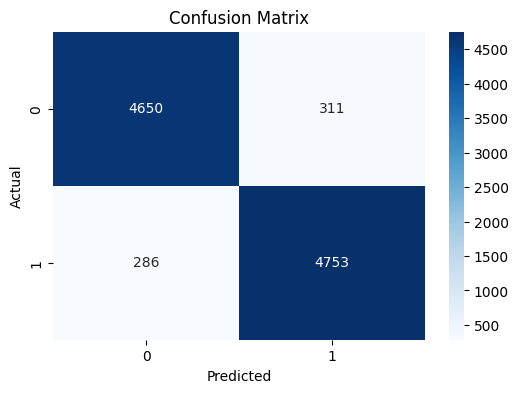

In [24]:
# Confusion Matrix ვიზუალიზაცია
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

### Fine Tuning
* ავიღოთ pre-trained model, გავწვრთნათ ეს მოდელი მოცემული use-case-ისთვის
* Expensive
* საჭიროა Training dataset
* Highly customised model დავალებისთვის

In [42]:
# Tweet sentiments (Positive, Neutral or Negative)
dataset = load_dataset("mteb/tweet_sentiment_extraction")
df = pd.DataFrame(dataset["train"])
df.head()

,id,text,label,label_text
0,cb774db0d1,"I`d have responded, if I were going",1,neutral
1,549e992a42,Sooo SAD I will miss you here in San Diego!!!,0,negative
2,088c60f138,my boss is bullying me...,0,negative
3,9642c003ef,what interview! leave me alone,0,negative
4,358bd9e861,"Sons of ****, why couldn`t they put them on t...",0,negative


In [43]:
# Choose pre-trained Model
model_name = "cardiffnlp/twitter-roberta-base"   # or "roberta-base"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3)

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at cardiffnlp/twitter-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [44]:
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128,
    )

tokenized_datasets = dataset.map(tokenize_function, batched=True)

Map:   0%|          | 0/3432 [00:00<?, ? examples/s]

In [45]:
# Create a smaller subset
small_train_dataset = tokenized_datasets["train"].shuffle(seed=42).select(range(1000))
small_eval_dataset = tokenized_datasets["test"].shuffle(seed=42).select(range(1000))

In [46]:
# ტრანსფორმერებს აქვთ Trainer class, თუმცა არ აქვს ევალუაციის ფუნქცია. 
# ამ ფუნქციას გადავაწვდით Trainer-ს მოდელის პერფორმანსის ევალუაციისთვის.
metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
   logits, labels = eval_pred
   predictions = np.argmax(logits, axis=-1)
   return metric.compute(predictions=predictions, references=labels)

In [85]:
training_args = TrainingArguments(
   output_dir="test_trainer",
   #evaluation_strategy="epoch",
   per_device_train_batch_size=1,  # Reduce batch size here
   per_device_eval_batch_size=1,    # Optionally, reduce for evaluation as well
   gradient_accumulation_steps=4
   )


trainer = Trainer(
   model=model,
   args=training_args,
   train_dataset=small_train_dataset,
   eval_dataset=small_eval_dataset,
   compute_metrics=compute_metrics,

)

trainer.train()

Step,Training Loss
500,0.780800


TrainOutput(global_step=750, training_loss=0.650380635579427, metrics={'train_runtime': 451.0057, 'train_samples_per_second': 6.652, 'train_steps_per_second': 1.663, 'total_flos': 197335063296000.0, 'train_loss': 0.650380635579427, 'epoch': 3.0})

In [86]:
trainer.evaluate()

{'eval_loss': 1.2093098163604736,
 'eval_accuracy': 0.756,
 'eval_runtime': 42.4096,
 'eval_samples_per_second': 23.58,
 'eval_steps_per_second': 23.58,
 'epoch': 3.0}

### RAG (Retrieval-Augmented Generation)

| Component     | Description                            |
| ------------- | -------------------------------------- |
| Tokenizer | გარდაქმნის კითხვას token-ებად     |
| Retriever | ეძებს მსგავს დოკუმენტებს   |
| Generator | იყენებს retrieved დოკუმენტებს პასუხის გენერაციისთის |

| უპირატესობა                       | ახსნა                                                                         |
| --------------------------------- | ----------------------------------------------------------------------------- |
| უმცირებს "ჰალუცინაციებს"    | პასუხები ეფუძნება რეალურ დოკუმენტებს, არა მხოლოდ მოდელის მეხსიერებას          |
| პასუხები კონტექსტიდან         | მომხმარებლის შეკითხვებს პასუხობს კონკრეტული დოკუმენტების შინაარსზე დაყრდნობით |
| მცირე მოდელით ძლიერი შედეგები| რთულ კითხვებზეც ზუსტი პასუხის გენერაცია შესაძლებელი ხდება                     |

Input Query

   ↓
   
Retriever (e.g., FAISS, BM25)

   ↓
   
Top-K Relevant Documents

   ↓
   
[Query + Documents] → Generator (e.g., BART)

   ↓
   
Generated Output

In [6]:
def extract_text_from_pdf(pdf_path):
    reader = PyPDF2.PdfReader(pdf_path)
    text = ""
    for page in reader.pages:
        text += page.extract_text()
    return text

In [7]:
text = extract_text_from_pdf("../../datasets/little_prince/little_prince.pdf")
print(text[2055:2255])

Once, when I was six years old, I saw a marvellous picture in a 
book on rainforests called Real-Life Stories. It depicted a boa constrictor swallowing a wild animal. Here is a replica of the picture.


In [8]:
# დაყოფა ტექსტის 100 - სიტყვიან ნაწილებად
def split_text_into_chunks(text, max_words=30):
    words = text.split()
    chunks = [" ".join(words[i:i+max_words]) for i in range(0, len(words), max_words)]
    return chunks

chunks = split_text_into_chunks(text)
print(chunks[0])

The Little PrinceI believe he escaped by hitching a ride with a flock of migrating wild birds.antoine de saint-exupéry The Little Prince alma booksI believe he escaped by hitching a


In [9]:
# რიცხვით ვექტორად გარდაქმნა
embedder = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = embedder.encode(chunks, convert_to_numpy=True)
print({chunks[0][:17]: [round(float(x), 2) for x in embeddings[0][:17]]})

{'The Little Prince': [0.04, 0.11, 0.03, 0.06, 0.08, 0.03, 0.02, -0.03, 0.01, 0.03, 0.0, -0.02, -0.03, -0.11, -0.0, -0.01, -0.05]}


In [10]:
# Build FAISS index
dimension = embeddings.shape[1]
index = faiss.IndexFlatL2(dimension)
index.add(embeddings)

In [11]:
def retrieve_relevant_chunks(question, k=10):
    question_embedding = embedder.encode([question], convert_to_numpy=True)
    _, indices = index.search(question_embedding, k)
    return [chunks[i] for i in indices[0]]

question = "What does the little prince ask to draw?"
retrieved_chunks = retrieve_relevant_chunks(question)

# Show retrieved chunks
print("Retrieved Chunks:")
for i, chunk in enumerate(retrieved_chunks):
    print(f"\n--- Chunk {i+1} ---\n{chunk}")

Retrieved Chunks:

--- Chunk 1 ---
head over the drawing:“Not that small… Look! It’s fallen asleep…” And so it was that I made the acquaintance of the little prince. III It took me a long time

--- Chunk 2 ---
to understand where he came from. The little prince, who asked me lots of questions, seemed never to hear my own. Little by little, things he said at random revealed

--- Chunk 3 ---
Anywhere. Straight ahead…”Then the little prince replied gravely:The Little Prince on Asteroid B 612

--- Chunk 4 ---
if you’re good, I’ll also give you a rope to tie it up with during the day . And a post.” The suggestion appeared to shock the little prince.“Tie it

--- Chunk 5 ---
history , mathematics and grammar, and I said to the little fellow (in something of a bad mood) that I didn’t know how to draw . He replied: “It doesn’t

--- Chunk 6 ---
The Little PrinceI believe he escaped by hitching a ride with a flock of migrating wild birds.antoine de saint-exupéry The Little Prince alma booksI beli

In [12]:
question = "What does the little prince ask to draw?"

# Make sure these are strings
retrieved_chunks = [str(c) for c in retrieved_chunks]

context = "\n\n".join(retrieved_chunks)

prompt = f"""Answer the question using ONLY the context.

Context:
{context}

Question:
{question}
"""

generator = pipeline("text2text-generation", model="google/flan-t5-large")

out = generator(
    prompt,
    max_new_tokens=80,   # better than max_length for generation
    do_sample=False,
    truncation=True      # IMPORTANT if context is long
)

print(out[0]["generated_text"])

Device set to use mps:0


a sheep


### RAG pipeline using `IngestionPipeline` for document chunking, `SentenceTransformer` for embedding generation, `ChromaDB` for vector search, and `FLAN-T5` for local answer generation
---

* [IngestionPipeline](https://docs.llamaindex.ai/en/stable/module_guides/loading/ingestion_pipeline/) – splits documents into overlapping chunks using `SentenceSplitter`
* [SentenceTransformer](https://huggingface.co/sentence-transformers) – encodes text chunks into dense semantic embeddings
* [ChromaDB](https://docs.trychroma.com/docs/overview/introduction) – stores and retrieves top-k relevant chunks via vector similarity
* [FLAN-T5](https://huggingface.co/google/flan-t5-large) – generates the final answer based on retrieved context and question

In [16]:
# Load PDF or text files
documents = SimpleDirectoryReader("../../datasets/little_prince").load_data()
print(documents[0])

Doc ID: cfcb769e-ab2e-4e6b-a970-0ae078853fde
Text: The Little Prince


In [17]:
# Chunk the document
ingestion_pipeline = IngestionPipeline(
    transformations=[SentenceSplitter(chunk_size=100, chunk_overlap=32)]
)
nodes = ingestion_pipeline.run(documents=documents) 
print(nodes[0])

Node ID: 647f34d9-e3fb-4c64-a440-5caefb43a308
Text: The Little Prince


In [18]:
# Compute embeddings using SentenceTransformer
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")
texts = [node.text for node in nodes]

embeddings = embedding_model.encode(texts, normalize_embeddings=True, show_progress_bar=True)

print(f"{len(embeddings)} embeddings computed")

2026-07-05 22:02:58,193 - INFO - Use pytorch device_name: mps
2026-07-05 22:02:58,193 - INFO - Load pretrained SentenceTransformer: all-MiniLM-L6-v2


Batches:   0%|          | 0/3 [00:00<?, ?it/s]

77 embeddings computed


In [19]:
# Create a Chroma collection and add data
client = chromadb.Client()

# Delete old collection if it already exists
try:
    client.delete_collection(name="document_chunks")
except Exception:
    pass

collection = client.get_or_create_collection(name="document_chunks")

ids = [f"chunk_{i}" for i in range(len(nodes))]
documents = [node.text for node in nodes]
metadatas = [{"chunk_id": i} for i in range(len(nodes))]
embeddings_list = embeddings.tolist()

collection.add(ids=ids, documents=documents, embeddings=embeddings_list, metadatas=metadatas)

print("Document chunks indexed in ChromaDB")

2026-07-05 22:04:31,762 - INFO - Anonymized telemetry enabled. See                     https://docs.trychroma.com/telemetry for more information.


Document chunks indexed in ChromaDB


In [23]:
# Accept user query
user_query = "Why does the little prince need a box for the sheep?"
query_embedding = embedding_model.encode(user_query, normalize_embeddings=True)

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

In [24]:
# Query ChromaDB for top-k matching chunks
results = collection.query(
    query_embeddings=[query_embedding.tolist()],
    n_results=5
)

# Extract retrieved text chunks
retrieved_chunks = results["documents"][0]

# Join chunks into one context
context = "\n\n".join(retrieved_chunks)

print(f"Retrieved {len(retrieved_chunks)} chunks for query")

Retrieved 5 chunks for query


In [25]:
for i, document in enumerate(retrieved_chunks):
    print(f"Rank {i+1}: {document}")
    print(f"Metadata: {results["metadatas"][0][i]}")
    print("-" * 50)

Rank 1: “I’m sure it’ll be enough. I’ve given you a very small sheep.”
He bent his head over the drawing:
“Not that small… Look! It’s fallen asleep…”
And so it was that I made the acquaintance of the little prince.
Metadata: {'chunk_id': 57}
--------------------------------------------------
Rank 2: The sheep you want is 
inside.”
But I was very surprised to see my young 
critic’s face light up:
“That’s exactly how I wanted it!
Metadata: {'chunk_id': 55}
--------------------------------------------------
Rank 3: Do you think this sheep 
needs a lot of grass?”
“Why?”
“Because my place is very small…”
Metadata: {'chunk_id': 56}
--------------------------------------------------
Rank 4: I want a sheep that will live a long time.”
Finally , my patience at an end, as I was in a 
hurry to start dismantling my engine, I scrib-
bled this drawing:
And I exclaimed:
“That’s the crate.
Metadata: {'chunk_id': 54}
--------------------------------------------------
Rank 5: Where is ‘home’ 
for you? W

In [26]:
# Format prompt and use FLAN-T5 to answer
prompt = f"""Answer the question using ONLY the context.

Context:
{context}

Question:
{user_query}
"""

In [28]:
# Load local FLAN-T5 model for generation
generator = pipeline("text2text-generation", model="google/flan-t5-large")
response = generator(prompt, max_new_tokens=150, do_sample=False, truncation=True)[0]["generated_text"]

Device set to use mps:0


In [30]:
# Show final answer
print("\nAnswer:")
print(response)


Answer:
Because it can be its house at night


#### Ways to Improve the Answer:

In [41]:
# Add instructions to the prompt
prompt = f"""You are a helpful assistant answering questions about "The Little Prince".

Use ONLY the context below to answer the question."

Context:
{context}

Question:
{user_query}

Answer in one or two full sentences, clearly and concisely.
"""

response = generator(prompt, max_new_tokens=150, do_sample=False, truncation=True)[0]["generated_text"]

print("\nAnswer:")
print(response)


Answer:
It can be its house at night
